# Longitud de ventana *L* y estrategias de desbalance (2.3)

Con la arquitectura seleccionada en el notebook 02 se compara:

1. **Longitud de ventana** *L* ∈ {24, 72, 168} h (pérdida ponderada).
2. **Desbalance de clases** con la mejor *L*: 
   - **Pérdida ponderada**: BCE con `pos_weight` = n_neg / n_pos (≈ 48) y CE con pesos balanceados N / (K·n_c).
   - **Submuestreo de horas sanas**: pérdida sin ponderar, pero cada época toma todas las horas positivas y una muestra aleatoria (nueva en cada época) de 10 horas sanas por positiva.

Ambas corrigen el desbalance en el *gradiente*, pero afectan de forma distinta a la **calibración**: se mide con diagramas de confiabilidad y el *Brier score* en validación.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, savefig

set_style()
pd.set_option("display.precision", 3)
FIG = ROOT / "entrega2" / "figures"
RES = ROOT / "entrega2" / "results"
RUNS = RES / "runs"


def load_run(name):
    m = json.loads((RUNS / name / "metrics.json").read_text())
    m["history"] = pd.read_csv(RUNS / name / "history.csv")
    return m

from sklearn.calibration import calibration_curve
from src.metrics import brier

stages = json.loads((RES / "stages.json").read_text())
arch, best_L = stages["arch"], stages["L"]
NAMES = {"gru": "GRU", "tcn": "TCN", "cnnlstm": "CNN-LSTM"}
print("arquitectura:", NAMES[arch], "| mejor L:", best_L, "| estrategia seleccionada:", stages["imbalance"])


arquitectura: CNN-LSTM | mejor L: 24 | estrategia seleccionada: weighted


## 1. Efecto de la longitud de ventana

In [2]:
def run_name(L):
    return f"arch_{arch}" if L == 72 else f"L_{arch}_{L}"

rows = []
for L in (24, 72, 168):
    m = load_run(run_name(L))
    rows.append({"L (h)": L, "PR-AUC": m["PR-AUC"], "ROC-AUC": m["ROC-AUC"], "recall@P≥0.80": m["recall@P≥0.80"],
                 "F1 macro": m["f1"]["macro"], "anticipación mediana (h)": m["lead_median_h"],
                 "fallas anticipadas": m["failures_anticipated"], "mejor época": m["best_epoch"],
                 "s/época": m["seconds"] / m["epochs"]})
wl = pd.DataFrame(rows).set_index("L (h)")
wl.to_csv(RES / "window_length.csv")
wl

,PR-AUC,ROC-AUC,recall@P≥0.80,F1 macro,anticipación mediana (h),fallas anticipadas,mejor época,s/época
L (h),,,,,,,,
24,0.996,1.0,1.000,0.941,24.0,1.000,6,13.861
72,0.995,1.0,0.991,0.963,24.0,0.992,11,23.043
168,0.988,1.0,0.990,0.937,24.0,0.992,8,47.795


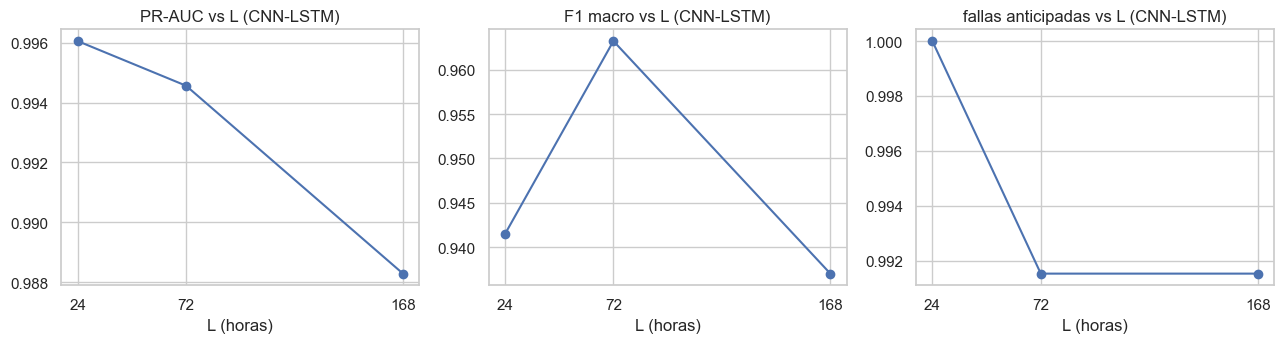

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["PR-AUC", "F1 macro", "fallas anticipadas"]):
    ax.plot(wl.index, wl[col], "-o")
    ax.set(title=f"{col} vs L ({NAMES[arch]})", xlabel="L (horas)", xticks=[24, 72, 168])
plt.tight_layout()
savefig(fig, "04_window_length", FIG)

## 2. Estrategias de desbalance y calibración

In [4]:
imb = {"pérdida ponderada": load_run(run_name(best_L)), "submuestreo de sanas": load_run(f"imb_{arch}_{best_L}_undersample")}
preds = {k: pd.read_parquet(RUNS / v["name"] / "val_preds.parquet") for k, v in imb.items()}
y = pd.read_parquet(ROOT / "data" / "interim" / "val.parquet")[["machineID", "datetime", "y_bin"]]
rows = []
for k, m in imb.items():
    p = preds[k].merge(y, on=["machineID", "datetime"])
    rows.append({"estrategia": k, "PR-AUC": m["PR-AUC"], "ROC-AUC": m["ROC-AUC"], "recall@P≥0.80": m["recall@P≥0.80"],
                 "umbral (P≥0.80)": m["umbral"], "F1 macro": m["f1"]["macro"], "Brier": brier(p["y_bin"], p["p_bin"]),
                 "p media (sanas)": p.loc[p["y_bin"] == 0, "p_bin"].mean(), "p media (positivas)": p.loc[p["y_bin"] == 1, "p_bin"].mean(),
                 "tasa real": p["y_bin"].mean(), "s/época": m["seconds"] / m["epochs"]})
im = pd.DataFrame(rows).set_index("estrategia")
im.to_csv(RES / "imbalance.csv")
im

,PR-AUC,ROC-AUC,recall@P≥0.80,umbral (P≥0.80),F1 macro,Brier,p media (sanas),p media (positivas),tasa real,s/época
estrategia,,,,,,,,,,
pérdida ponderada,0.996,1.0,1.000,0.048,0.941,0.001,0.001,0.995,0.018,13.861
submuestreo de sanas,0.989,1.0,0.993,0.007,0.945,0.001,0.001,0.980,0.018,3.826


pérdida ponderada                     submuestreo de sanas  \
                             n    p_media frac_pos                    n   
p_bin                                                                     
[0.0, 0.02)             140910  6.745e-05    0.000               140984   
[0.02, 0.05)               122  3.035e-02    0.008                  104   
[0.05, 0.1)                 48  7.393e-02    0.000                   39   
[0.1, 0.2)                  41  1.460e-01    0.073                   38   
[0.2, 0.3)                  26  2.519e-01    0.077                   25   
[0.3, 0.5)                  34  3.827e-01    0.118                   34   
[0.5, 0.7)                  40  5.973e-01    0.100                   32   
[0.7, 0.9)                  47  8.180e-01    0.340                   48   
[0.9, 0.98)                 61  9.493e-01    0.344                   99   
[0.98, 1.0)               2671  9.993e-01    0.974                 2597   

                                    
                p_media   frac_pos  
p_bin                               
[0.0, 0.02)   5.193e-05  1.560e-04  
[0.02, 0.05)  3.152e-02  3.846e-02  
[0.05, 0.1)   6.845e-02  1.282e-01  
[0.1, 0.2)    1.431e-01  1.053e-01  
[0.2, 0.3)    2.437e-01  8.000e-02  
[0.3, 0.5)    3.993e-01  1.765e-01  
[0.5, 0.7)    6.070e-01  3.125e-01  
[0.7, 0.9)    8.003e-01  3.333e-01  
[0.9, 0.98)   9.533e-01  6.263e-01  
[0.98, 1.0)   9.982e-01  9.707e-01

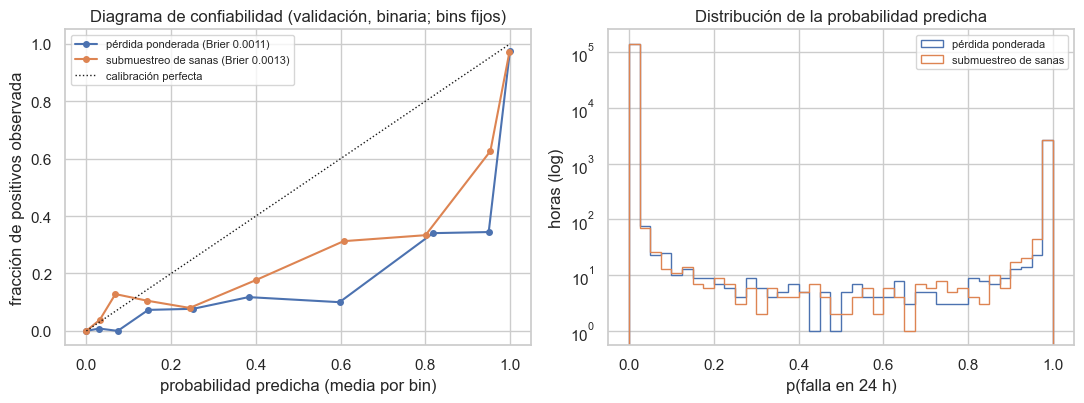

In [5]:
BINS = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.98, 1.0001]
rel = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k, m in imb.items():
    p = preds[k].merge(y, on=["machineID", "datetime"])
    g = p.groupby(pd.cut(p["p_bin"], BINS, right=False), observed=True).agg(n=("y_bin", "size"), p_media=("p_bin", "mean"), frac_pos=("y_bin", "mean"))
    rel[k] = g
    axes[0].plot(g["p_media"], g["frac_pos"], "-o", ms=4, label=f"{k} (Brier {im.loc[k, 'Brier']:.4f})")
    axes[1].hist(p["p_bin"], bins=40, histtype="step", lw=1.5, label=k, log=True)
axes[0].plot([0, 1], [0, 1], "k:", lw=1, label="calibración perfecta")
axes[0].set(title="Diagrama de confiabilidad (validación, binaria; bins fijos)", xlabel="probabilidad predicha (media por bin)",
            ylabel="fracción de positivos observada")
axes[1].set(title="Distribución de la probabilidad predicha", xlabel="p(falla en 24 h)", ylabel="horas (log)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
savefig(fig, "05_calibration", FIG)
rel_tab = pd.concat(rel, axis=1)
rel_tab.to_csv(RES / "reliability_bins.csv")
rel_tab

**Cómo afecta cada estrategia a la calibración.** El 99.7 % de las horas de validación cae en los dos extremos (p < 0.02 o p > 0.98) y ahí ambas estrategias están bien calibradas: el problema es casi determinista (error asociado 24 h antes, escalón de sensores 48 h antes). Las diferencias aparecen en las ≈ 250 horas intermedias, donde las dos **sobreestiman** la probabilidad, pero en distinto grado:

- **Pérdida ponderada** con `pos_weight` = n_neg / n_pos equivale a entrenar con una prior de 50 %, así que la salida es *p*(falla | x) bajo esa prior y no bajo la real (≈ 2 %). En las horas ambiguas la sobreestimación es grande: en el bin 0.7–0.9 el modelo predice ≈ 0.8 y se observa ≈ 0.3; en 0.9–0.98 predice 0.95 y se observa ≈ 0.3.
- **Submuestreo de sanas** 10:1 equivale a una prior de ≈ 9 %, por lo que sobreestima menos (en 0.9–0.98 predice 0.95 y se observa ≈ 0.6). El sesgo es conocido y se puede deshacer en los logits restando log(1/β), con β la fracción de negativos conservada. Cada época ve solo el 20 % de las horas sanas: entrenar es ≈ 4× más rápido, pero el PR-AUC es algo menor y el entrenamiento más ruidoso.

El Brier score es bajo en ambos casos (≈ 0.001) porque lo dominan los extremos, así que no distingue las estrategias; el diagrama de confiabilidad sí. La **ordenación** (PR-AUC, ROC-AUC) apenas cambia; lo que cambia es la escala de la probabilidad en la zona ambigua, que es justamente la que importa para elegir el umbral y para la política de mantenimiento de la semana 3 (donde se recalibrará con *temperature scaling* si hace falta).